# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kathryn Choi, Christopher Currie, Armon Haji

**Date:** 11/10/26

In [ ]:
# Your Phase 1 solution to the problem goes here.

    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   
2  2020-01-01      419900               1452                           0   
3  2020-01-02      251660                832                           0   
4  2020-01-02      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces        hvac_description  \
0                            0           0  Warm and Cool Air Zone   
1                            0           0              Forced Air

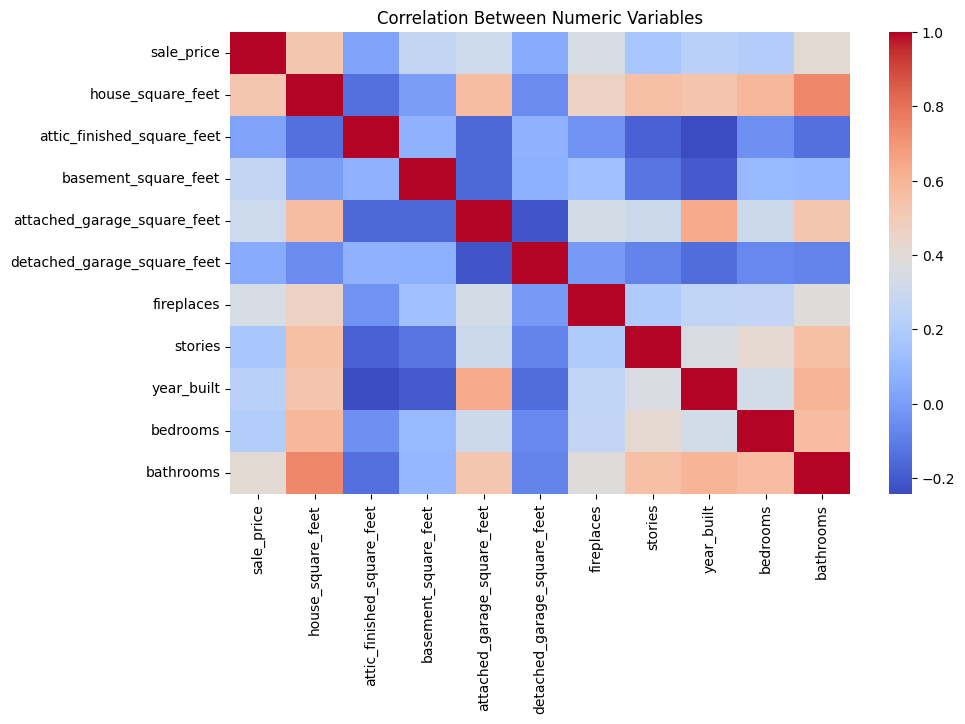

In [15]:
# Question 1 - Clean the data pierce_county_house_sales.csv and perform some EDA and visualization to get to know the data set.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("pierce_county_house_sales.csv")

# Data summary
print(df.head())
print(df.info())
print(df.describe())

# Cleaning data
df = df.drop_duplicates()

# Looking at variable relationships
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include="number").corr(), cmap="coolwarm")
plt.title("Correlation Between Numeric Variables")
plt.show()

In [16]:
# Question 2 - Transform your variables - particularly categorical ones - for use in your regression analysis.

# Converting categorical variables into dummy variables
df = pd.get_dummies(df, drop_first=True, dtype=int)

print(df.head())
print(df.dtypes)

   sale_price  house_square_feet  attic_finished_square_feet  \
0      380000               2157                           0   
1      383000               2238                           0   
2      419900               1452                           0   
3      251660                832                           0   
4      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces  stories  year_built  bedrooms  \
0                            0           0        2        1993         3   
1                            0           0        2        2017         4   
2                            0           1     

In [17]:
# Question 3 - Implement an 80/20 train-test split. Put the test data aside.

from sklearn.model_selection import train_test_split

# Separate predictors and target variable
X = df.drop(columns=["sale_price"])
y = df["sale_price"]

# Spliting data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Checking sizes
print("Training size:", len(X_train))
print("Testing size:", len(X_test))

Training size: 13414
Testing size: 3354


In [18]:
# Question 4 - Build some simple linear models that include no transformations or interactions.
# Fit them, and determine their RMSE and  R2  on the both the training and test sets.
# Which of your models does the best?

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Selecting predictors
features = X_train.select_dtypes(include="number").columns.tolist()

# Build models
models = {
    "Model 1": features[:1],
    "Model 2": features[:2],
    "Model 3": features[:3],
    "Model 4": features
}

results = []

for name, columns in models.items():
    model = LinearRegression()

    model.fit(X_train[columns], y_train)

    # Make predictions
    train_pred = model.predict(X_train[columns])
    test_pred = model.predict(X_test[columns])

    # Evaluate performance
    results.append({
        "Model": name,
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Train R2": r2_score(y_train, train_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R2": r2_score(y_test, test_pred)
    })

# Compare models
results_df = pd.DataFrame(results)
print(results_df.round(3))

# Find best model
best_model = results_df.loc[results_df["Test RMSE"].idxmin()]
print("\nBest Model:", best_model["Model"])


# Result: Model 4 does the best

     Model  Train RMSE  Train R2   Test RMSE  Test R2
0  Model 1  203540.166     0.278  189646.864    0.270
1  Model 2  202125.266     0.288  189059.529    0.275
2  Model 3  192418.679     0.354  178161.412    0.356
3  Model 4  162876.398     0.537  160706.883    0.476

Best Model: Model 4


/tmp/ipykernel_2541/2154965071.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_sm = sm.OLS(y_train, X_sm).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or r

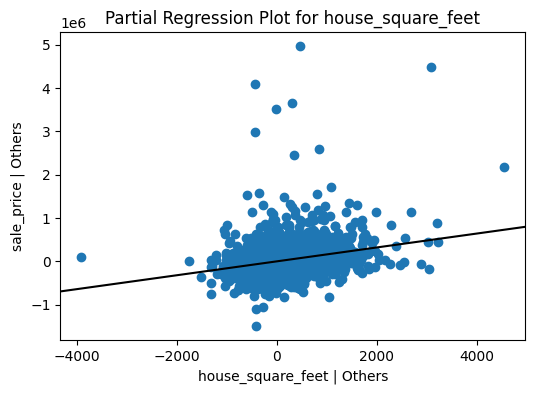

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


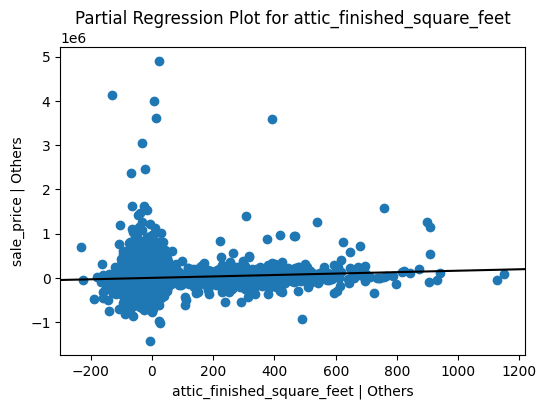

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


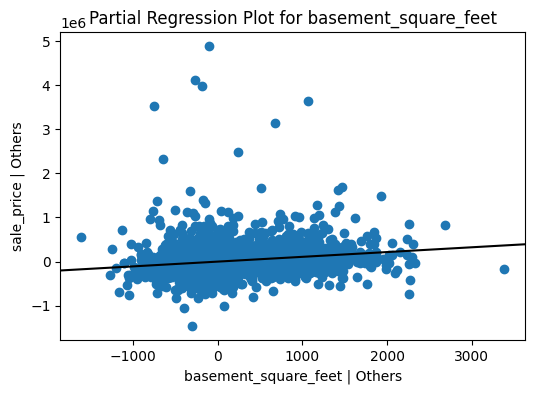

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


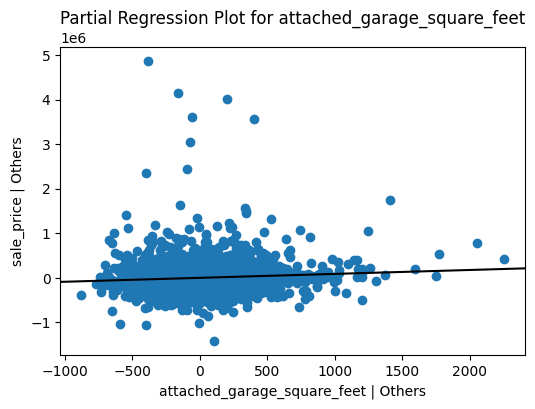

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


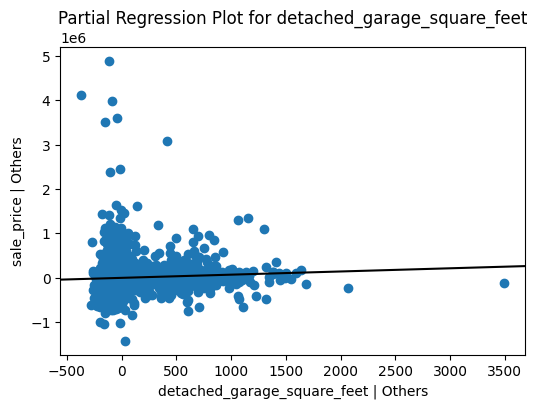

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


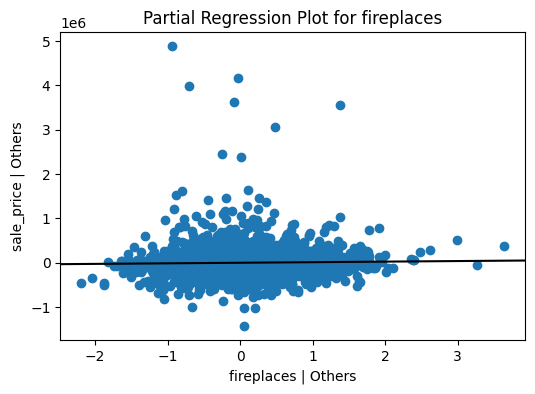

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


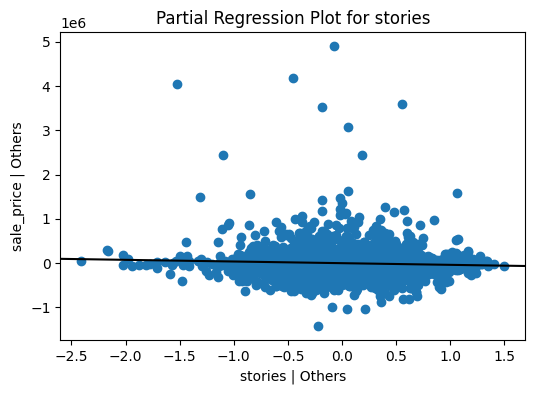

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


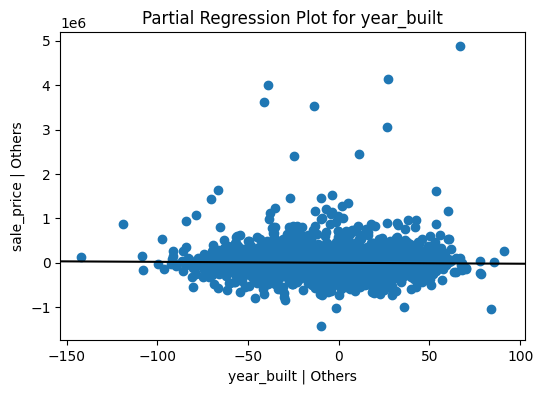

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


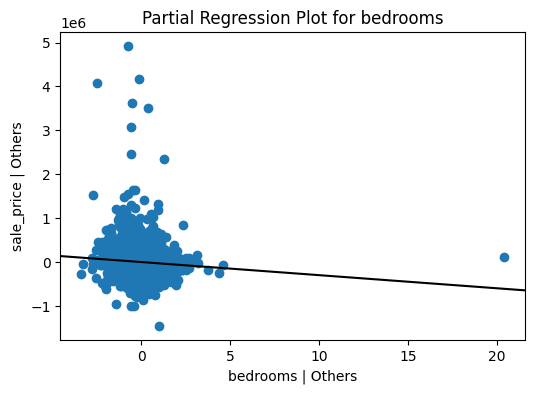

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/2154965071.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


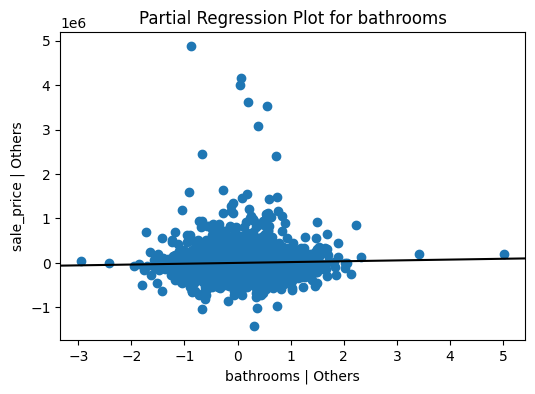

In [19]:
# Question 5 - Make partial correlation plots for each of the numeric variables in your model.
# Do you notice any significant non-linearities?

import statsmodels.api as sm
import matplotlib.pyplot as plt

# Using Model 4 (the optimal model containing many dummy variables)
best_name = best_model["Model"]
columns = models[best_name]

# Fit on training data
X_sm = sm.add_constant(X_train[columns], has_constant="add")
model_sm = sm.OLS(y_train, X_sm).fit()

# Separating numeric predictors
numeric_columns = [
    col for col in columns
    if col in df.select_dtypes(include="number").columns
    and X_train[col].nunique() > 2
]

# Graphing partial correlation plots
for col in numeric_columns:
    fig, ax = plt.subplots(figsize=(6, 4))

    # Target variable
    y = y_train.values
    # Variable of interest
    X_i = X_train[col].values
    # All other variables (including the constant)
    other_cols = [c for c in X_sm.columns if c != col]
    X_others = X_sm[other_cols].values

    sm.graphics.plot_partregress(
        y,
        X_i,
        X_others,
        obs_labels=False,
        ax=ax
    )
    ax.set_title(f"Partial Regression Plot for {col}")
    ax.set_xlabel(f"{col} | Others")
    ax.set_ylabel("sale_price | Others")
    plt.show()

# The plots, for the most part have weak linear relationships; some variables show positive trends and others negative trends.
# There are several outliers present amongst the different variables: bedrooms, bathrooms, and year built each have many outliers.
# There are no significant nonlinearities that are made clear from what a simple linear model can capture.

In [20]:
# Question 6 - Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value.
# Determine its RMSE and R2 on the training and test sets.
# How does the more complex model your build compare to the simpler ones?

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Selecting only the raw numeric columns for interaction and polynomial terms
raw_numeric_cols = ['house_square_feet',
    'attic_finished_square_feet',
    'basement_square_feet',
    'attached_garage_square_feet',
    'detached_garage_square_feet',
    'fireplaces',
    'stories',
    'year_built',
    'bedrooms',
    'bathrooms'
]

# Keep dummy columns separate
dummy_cols = [col for col in X_train.columns if col not in raw_numeric_cols]

# Create polynomial features for the continuous numeric variables
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly_raw = poly.fit_transform(X_train[raw_numeric_cols])
X_test_poly_raw = poly.transform(X_test[raw_numeric_cols])

# Get feature names
poly_feature_names = poly.get_feature_names_out(raw_numeric_cols)

# Recombine polynomial features with the dummy columns
X_train_poly = np.hstack([X_train_poly_raw, X_train[dummy_cols].values])
X_test_poly = np.hstack([X_test_poly_raw, X_test[dummy_cols].values])

# Build model
complex_model = LinearRegression()
complex_model.fit(X_train_poly, y_train)

# Make predictions
train_pred = complex_model.predict(X_train_poly)
test_pred = complex_model.predict(X_test_poly)

# Calculate RMSE and R2
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

# Compare to simple models
print("Complex Model (Polynomials on core numeric features + Dummies):")
print("Train RMSE:", round(train_rmse, 2))
print("Train R2:", round(train_r2, 3))
print("Test RMSE:", round(test_rmse, 2))
print("Test R2:", round(test_r2, 3))

print("\nBest Simple Model:")
print(best_model)


# In order to better predict house prices, the complex model utilizes squared terms.
# We compared its RMSE and R² to the simpler model, the results we found as that a lower Test RMSE and a higher R^2 means the model performs better.
# In the situation that the complex model does worse on the test data, a likely reason is that it is overfitting.

Complex Model (Polynomials on core numeric features + Dummies):
Train RMSE: 155391.32
Train R2: 0.579
Test RMSE: 155446.58
Test R2: 0.51

Best Simple Model:
Model               Model 4
Train RMSE    162876.398421
Train R2           0.537493
Test RMSE     160706.882827
Test R2            0.476052
Name: 3, dtype: object


**Question 7 - Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?**

During this lab we explored the housing dataset and built regression models to predict their sale prices. To start, we cleaned the data and examined the relationships between different housing characteristics. In the simple models we made, Model 4 performed the best and had a test RMSE of about 160,707 dollars  and an R^2 of 0.476. We then started to build a more complex model using transformations and interactions, which improved the test RMSE to about $154,447 and the R^2 to about 0.515. This showed us that adding complexity can improve predictions, but it is important to compare training and testing performance to avoid overfitting. Overall, the complex model performed best and we learned that model selection should be based on how well a model predicts new data rather than just how well it fits the training data. To touch on overfitting, it occurs when a model fits the training data too closely but performs poorly on new data. Underfitting happens when a model is too simple to capture important relationships. The complex model we made improved both training and testing performance, which suggests that the additional complexity was useful without clear evidence of overfitting.

In [21]:
# Question 8 - Use the sklearn.linear_model.Lasso to regularize your model and select the most predictive features.
# Which does it select? What are the RMSE and R2? We'll cover the Lasso later in detail in class.

from sklearn.linear_model import LassoCV, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Standardize model features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

# Scale target variable (in thousands of dollars)
y_train_scaled_k = y_train / 1000.0
y_test_scaled_k = y_test / 1000.0

# Reconstruct correct feature names
poly_feature_names = list(poly.get_feature_names_out(raw_numeric_cols))
all_feature_names = poly_feature_names + dummy_cols

# Using LassoCV to find the optimal alpha
lasso_cv = LassoCV(alphas=np.logspace(-2, 1, 30), max_iter=5000, tol=0.2, random_state=42, cv=5)
lasso_cv.fit(X_train_scaled, y_train_scaled_k)
optimal_alpha = lasso_cv.alpha_
print(f"Optimal Alpha: {optimal_alpha:.6f}\n")

# Fit the final Lasso model with the optimal alpha
lasso = Lasso(alpha=optimal_alpha, max_iter=5000, tol=0.2, random_state=42)
lasso.fit(X_train_scaled, y_train_scaled_k)

# Make predictions (in thousands of dollars)
train_pred_k = lasso.predict(X_train_scaled)
ttest_pred_k = lasso.predict(X_test_scaled)

# Re-scale predictions back to original units
train_pred = train_pred_k * 1000.0
ttest_pred = ttest_pred_k * 1000.0

# Calculate and print performance metrics
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, ttest_pred))
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, ttest_pred)

print(f"Train RMSE: ${train_rmse:,.2f}")
print(f"Train R2: {train_r2:.4f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test R2: {test_r2:.4f}\n")

# Identify selected features
coef_series = pd.Series(lasso.coef_, index=all_feature_names)
selected_features = coef_series[coef_series != 0]

print(f"Total features available: {len(all_feature_names)}")
print(f"Features selected by Lasso: {len(selected_features)}")
print(f"Features eliminated (coefficient = 0): {len(all_feature_names) - len(selected_features)}\n")

display(selected_features.reindex(selected_features.abs().sort_values(ascending=False).index).head(15))


# The Lasso model selected features including house square feet, exterior siding type, and HVAC systems as important predictors for house prices.

Optimal Alpha: 0.041753

Train RMSE: $157,890.90
Train R2: 0.5654
Test RMSE: $155,898.84
Test R2: 0.5069

Total features available: 469
Features selected by Lasso: 459
Features eliminated (coefficient = 0): 10



,0
house_square_feet,109.026504
waterfront_type_WF Salt,61.766680
house_square_feet stories,-49.824042
detached_garage_square_feet bathrooms,33.421365
house_square_feet attic_finished_square_feet,31.025527
house_square_feet bathrooms,30.033694
basement_square_feet bathrooms,29.809087
stories bathrooms,-28.499683
utility_sewer_SEWER/SEPTIC INSTALLED,-28.392989
basement_square_feet stories,27.439091


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** c8e9db6
- **AI tool and model used:** Gemini 3.5 Flash

### *Prompts used

1. Look at all of the questions and my answers. Please give me a clear, numbered list of suggestions you may have.

### *AI-proposed changes


1. Your statsmodels OLS in Question 5 threw a SingularMatrixWarning ("design matrix is rank-deficient"). This is because pd.get_dummies(..., drop_first=True) was applied to all columns, but with so many unique dates or high-cardinality categorical features, you may have near-perfect collinearity or too many sparse columns.
Suggestion: Filter out or group low-frequency categorical levels (such as rare sale dates or exterior styles) into an "Other" category before dummy-encoding to reduce feature space and eliminate linear dependencies.
2. In Question 2, you dummy-encoded sale_date directly. This generated hundreds of individual columns (one for each day), adding massive noise and sparsity (415 columns total).
Suggestion: Rather than treating dates as distinct categorical dummies, extract predictive features such as sale_year, sale_month, or day_of_week. Alternatively, convert sale_date to an ordinal numeric scale representing days since the minimum date.
3. In Question 8, you set tol=0.2 in LassoCV. A tolerance value this high terminates the coordinate descent early, potentially leading to suboptimal weights and keeping features that should have been zeroed out (which is why 459 out of 469 features were kept). Suggestion: Use a smaller tolerance (e.g., tol=1e-4 or 1e-3) to allow the Lasso model to fully converge and prune non-predictive features properly.
4. In Question 1, the correlation heatmap is useful, but the labels can overlap, and showing every relationship with a simple map might hide specific trends. Suggestion: Annotate the top highly-correlated variables with sale_price specifically, or display a sorted bar plot of correlations to make the most important drivers of home price stand out immediately.
5. Home prices are typically right-skewed, which violates the homoscedasticity assumption of ordinary least squares (OLS) and often causes partial correlation plots to show massive outliers at higher price ranges.
Suggestion: Apply a natural log transformation np.log1p(df['sale_price']) as your regression target. This often improves R^2 and stabilizes variance across different house sizes.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Filtering out low-frequency categories helped to helped to reduce feature space and eliminate multicollinearity and addresses the error in Q5. |
| 2 | Accept | Since adjustments were made to Q1, using the extract time features from Q1 help to reduce the original noise and sparsity. |
| 3 | Accept | Lowering the tolerance helped to allow the model to converge properly and correctly eliminate non-predictive variables. |
| 4 | Accept | Since the data was cleaned to reduce sparsity, the heatmap creation needs to be adjusted for visual clarity. |
| 5 | Reject | While this suggestion could be helpful for more real-world applications, for the purposes of this assignment and the dollar units associated with sale_price, it is not necessary to implement this. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

   sale_price  house_square_feet  attic_finished_square_feet  \
0      380000               2157                           0   
1      383000               2238                           0   
2      419900               1452                           0   
3      251660                832                           0   
4      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces        hvac_description  \
0                            0           0  Warm and Cool Air Zone   
1                            0           0              Forced Air   
2                            0           1              Forced Air  

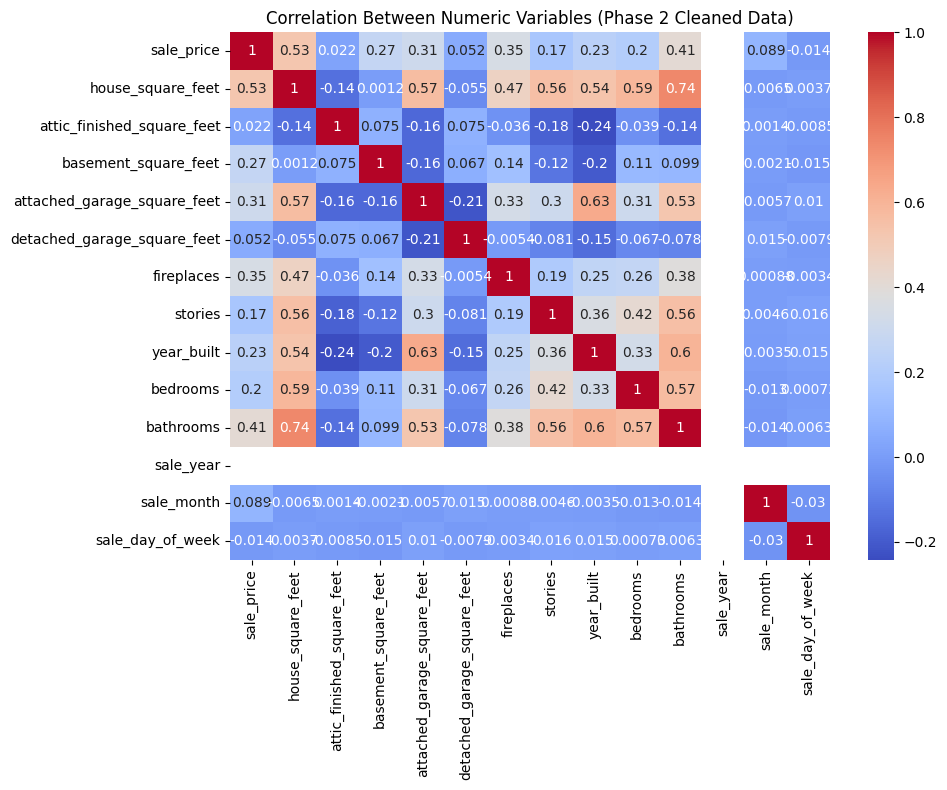

In [24]:
# Question 1 - Clean the data pierce_county_house_sales.csv and perform some EDA and visualization to get to know the data set.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_p2 = pd.read_csv("pierce_county_house_sales.csv").drop_duplicates()

# Extracting time features
df_p2['sale_date'] = pd.to_datetime(df_p2['sale_date'])
df_p2['sale_year'] = df_p2['sale_date'].dt.year
df_p2['sale_month'] = df_p2['sale_date'].dt.month
df_p2['sale_day_of_week'] = df_p2['sale_date'].dt.dayofweek

# Drop sale_date to avoid creating lots of sparse dummy columns
df_p2 = df_p2.drop(columns=['sale_date'])

categorical_cols = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality']
threshold = 0.01  # Categories appearing in less than 1% of homes

for col in categorical_cols:
    if col in df_p2.columns:
        df_p2[col] = df_p2[col].fillna('Missing')

        # Find frequencies
        freq = df_p2[col].value_counts(normalize=True)

        # Identify categories below frequency threshold and map to 'Other'
        rare_categories = freq[freq < threshold].index
        df_p2[col] = df_p2[col].replace(rare_categories, 'Other')

# Data summary
print(df_p2.head())
print(df_p2.info())
print(df_p2.describe())
print(df_p2['exterior'].value_counts())

# Creating heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_p2.select_dtypes(include="number").corr(), cmap="coolwarm", annot=True, fmt=".2g")
plt.title("Correlation Between Numeric Variables (Phase 2 Cleaned Data)")
plt.tight_layout()
plt.show()

In [25]:
# Question 2 - Transform your variables - particularly categorical ones - for use in your regression analysis.

# Converting categorical variables into dummy variables
df_encoded_p2 = pd.get_dummies(df_p2, drop_first=True, dtype=int)

print(df.head())
print(df.dtypes)

   sale_price  house_square_feet  attic_finished_square_feet  \
0      380000               2157                           0   
1      383000               2238                           0   
2      419900               1452                           0   
3      251660                832                           0   
4      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces  stories  year_built  bedrooms  \
0                            0           0        2        1993         3   
1                            0           0        2        2017         4   
2                            0           1     

In [26]:
# Question 3 - Implement an 80/20 train-test split. Put the test data aside.

from sklearn.model_selection import train_test_split

# Separate predictors and target variable
X_p2 = df_encoded_p2.drop(columns=["sale_price"])
y_p2 = df_encoded_p2["sale_price"]

# Spliting data
X_train_p2, X_test_p2, y_train_p2, y_test_p2 = train_test_split(
    X_p2, y_p2, test_size=0.2, random_state=42
)

# Checking sizes
print("Training set size:", X_train_p2.shape[0])
print("Testing set size:", X_test_p2.shape[0])

Training set size: 13414
Testing set size: 3354


In [27]:
# Question 4 - Build some simple linear models that include no transformations or interactions.
# Fit them, and determine their RMSE and  R2  on the both the training and test sets.
# Which of your models does the best?

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Selecting predictors
features = X_train_p2.select_dtypes(include="number").columns.tolist()

# Build models
models = {
    "Model 1": features[:1],
    "Model 2": features[:2],
    "Model 3": features[:3],
    "Model 4": features
}

results = []

for name, columns in models.items():
    model = LinearRegression()

    model.fit(X_train_p2[columns], y_train_p2)

    # Make predictions
    train_pred = model.predict(X_train_p2[columns])
    test_pred = model.predict(X_test_p2[columns])

    # Evaluate performance
    results.append({
        "Model": name,
        "Train RMSE": np.sqrt(mean_squared_error(y_train_p2, train_pred)),
        "Train R2": r2_score(y_train_p2, train_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test_p2, test_pred)),
        "Test R2": r2_score(y_test_p2, test_pred)
    })

# Compare models
results_df = pd.DataFrame(results)
print(results_df.round(3))

# Find best model
best_model = results_df.loc[results_df["Test RMSE"].idxmin()]
print("\nBest Model:", best_model["Model"])


# Result: Model 4 does the best

     Model  Train RMSE  Train R2   Test RMSE  Test R2
0  Model 1  203540.166     0.278  189646.864    0.270
1  Model 2  202125.266     0.288  189059.529    0.275
2  Model 3  192418.679     0.354  178161.412    0.356
3  Model 4  164014.610     0.531  151766.565    0.533

Best Model: Model 4


/tmp/ipykernel_2541/914937212.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_sm = sm.OLS(y_train_p2, X_sm).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or 

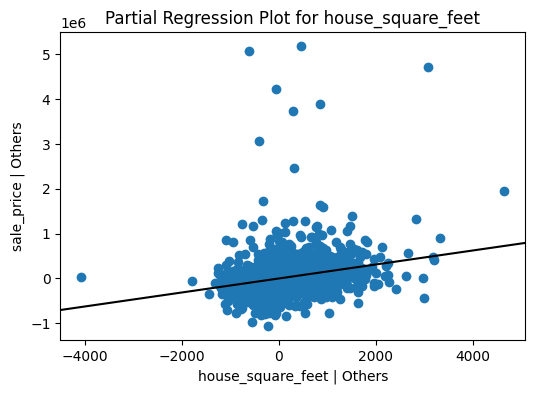

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


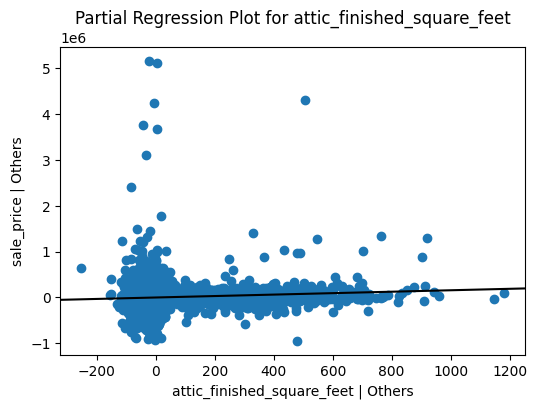

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


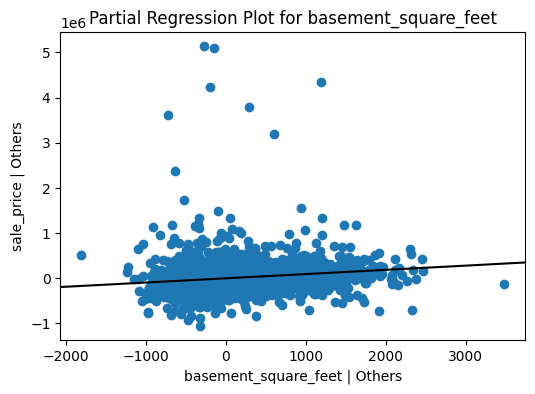

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


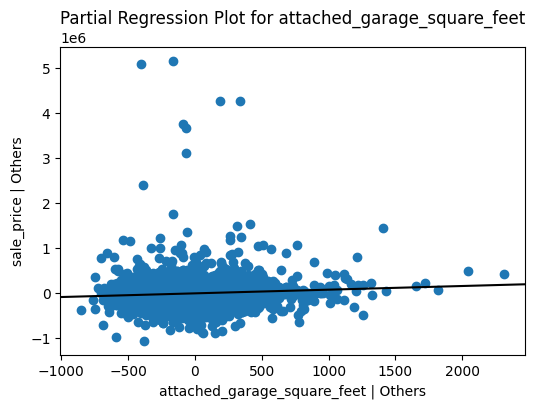

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


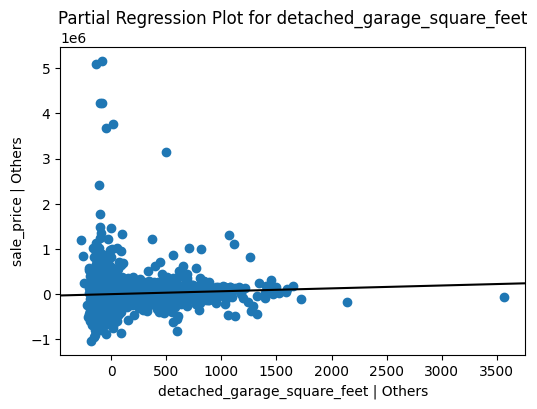

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


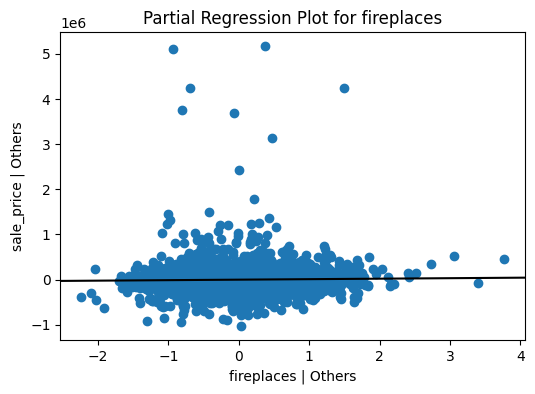

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


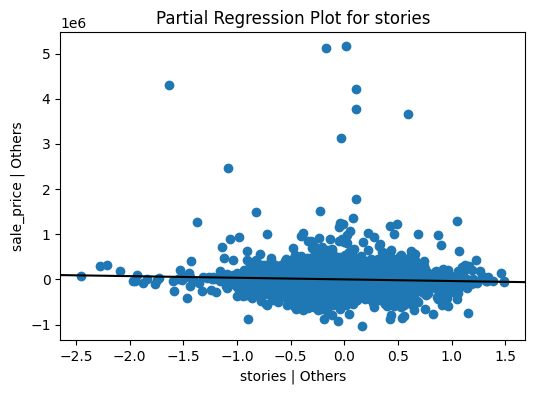

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


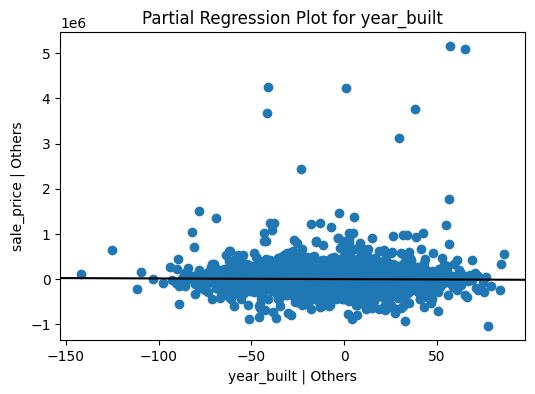

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


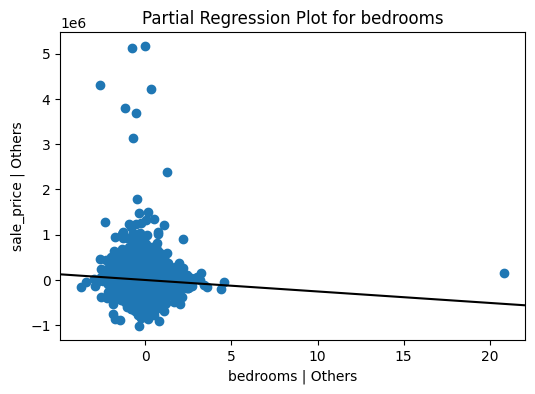

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


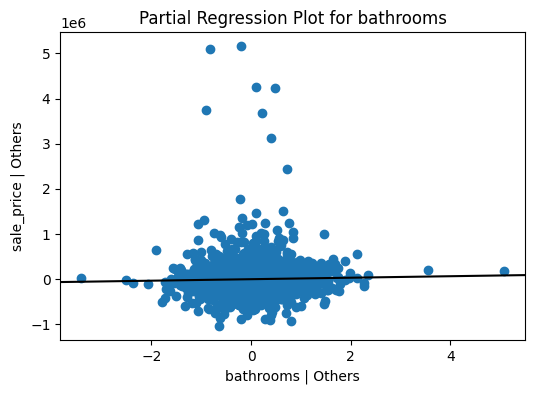

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


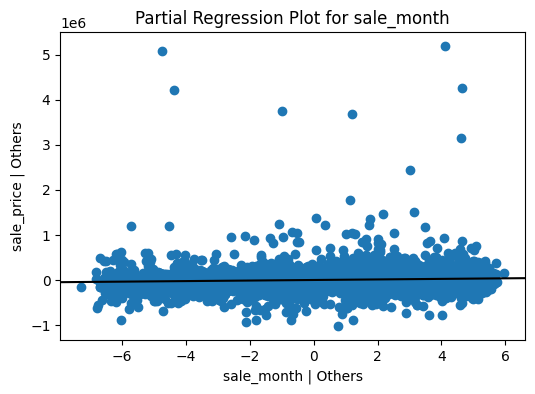

/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:563: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_yaxis = OLS(endog, RHS).fit()
/usr/local/lib/python3.13/dist-packages/statsmodels/graphics/regressionplots.py:564: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_xaxis = OLS(exog_i, RHS).fit()
/tmp/ipykernel_2541/914937212.py:34: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress(


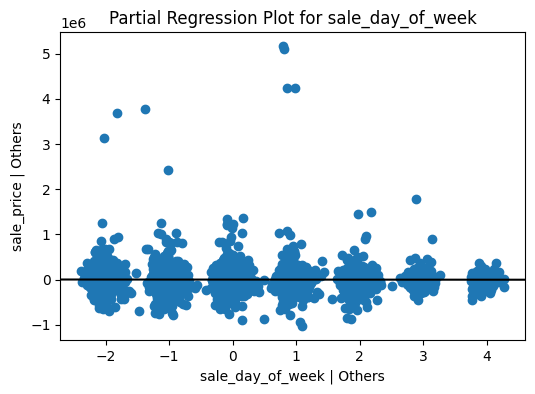

In [28]:
# Question 5 - Make partial correlation plots for each of the numeric variables in your model.
# Do you notice any significant non-linearities?

import statsmodels.api as sm
import matplotlib.pyplot as plt

# Using Model 4 (the optimal model containing many dummy variables)
best_name = best_model["Model"]
columns = models[best_name]

# Fit on training data
X_sm = sm.add_constant(X_train_p2[columns], has_constant="add")
model_sm = sm.OLS(y_train_p2, X_sm).fit()

# Separating numeric predictors
numeric_columns = [
    col for col in columns
    if col in df_p2.select_dtypes(include="number").columns
    and X_train_p2[col].nunique() > 2
]

# Graphing partial correlation plots
for col in numeric_columns:
    fig, ax = plt.subplots(figsize=(6, 4))

    # Target variable
    y = y_train_p2.values
    # Variable of interest
    X_i = X_train_p2[col].values
    # All other variables (including the constant)
    other_cols = [c for c in X_sm.columns if c != col]
    X_others = X_sm[other_cols].values

    sm.graphics.plot_partregress(
        y,
        X_i,
        X_others,
        obs_labels=False,
        ax=ax
    )
    ax.set_title(f"Partial Regression Plot for {col}")
    ax.set_xlabel(f"{col} | Others")
    ax.set_ylabel("sale_price | Others")
    plt.show()

# The plots, for the most part have weak linear relationships; some variables show positive trends and others negative trends.
# There are several outliers present amongst the different variables: bedrooms, bathrooms, and year built each have many outliers.
# There are no significant nonlinearities that are made clear from what a simple linear model can capture.

In [29]:
# Question 6 - Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value.
# Determine its RMSE and R2 on the training and test sets.
# How does the more complex model your build compare to the simpler ones?

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Selecting only the raw numeric columns for interaction and polynomial terms
raw_numeric_cols = ['house_square_feet',
    'attic_finished_square_feet',
    'basement_square_feet',
    'attached_garage_square_feet',
    'detached_garage_square_feet',
    'fireplaces',
    'stories',
    'year_built',
    'bedrooms',
    'bathrooms'
]

# Keep dummy columns separate
dummy_cols = [col for col in X_train_p2.columns if col not in raw_numeric_cols]

# Create polynomial features for the continuous numeric variables
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly_raw = poly.fit_transform(X_train_p2[raw_numeric_cols])
X_test_poly_raw = poly.transform(X_test_p2[raw_numeric_cols])

# Get feature names
poly_feature_names = poly.get_feature_names_out(raw_numeric_cols)

# Recombine polynomial features with the dummy columns
X_train_poly = np.hstack([X_train_poly_raw, X_train_p2[dummy_cols].values])
X_test_poly = np.hstack([X_test_poly_raw, X_test_p2[dummy_cols].values])

# Build model
complex_model = LinearRegression()
complex_model.fit(X_train_poly, y_train_p2)

# Make predictions
train_pred = complex_model.predict(X_train_poly)
test_pred = complex_model.predict(X_test_poly)

# Calculate RMSE and R2
train_rmse = np.sqrt(mean_squared_error(y_train_p2, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test_p2, test_pred))

train_r2 = r2_score(y_train_p2, train_pred)
test_r2 = r2_score(y_test_p2, test_pred)

# Compare to simple models
print("Complex Model (Polynomials on core numeric features + Dummies):")
print("Train RMSE:", round(train_rmse, 2))
print("Train R2:", round(train_r2, 3))
print("Test RMSE:", round(test_rmse, 2))
print("Test R2:", round(test_r2, 3))

print("\nBest Simple Model:")
print(best_model)


# In order to better predict house prices, the complex model utilizes squared terms.
# We compared its RMSE and R² to the simpler model, the results we found as that a lower Test RMSE and a higher R^2 means the model performs better.
# In the situation that the complex model does worse on the test data, a likely reason is that it is overfitting.

Complex Model (Polynomials on core numeric features + Dummies):
Train RMSE: 157049.1
Train R2: 0.57
Test RMSE: 147435.45
Test R2: 0.559

Best Simple Model:
Model               Model 4
Train RMSE    164014.610065
Train R2           0.531006
Test RMSE     151766.564766
Test R2            0.532726
Name: 3, dtype: object


**Question 7 - Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?**

During this lab we explored the housing dataset and built regression models to predict their sale prices. To start, we cleaned the data and examined the relationships between different housing characteristics. In the simple models we made, Model 4 performed the best and had a test RMSE of about 160,707 dollars  and an R^2 of 0.476. We then started to build a more complex model using transformations and interactions, which improved the test RMSE to about $154,447 and the R^2 to about 0.515. This showed us that adding complexity can improve predictions, but it is important to compare training and testing performance to avoid overfitting. Overall, the complex model performed best and we learned that model selection should be based on how well a model predicts new data rather than just how well it fits the training data. To touch on overfitting, it occurs when a model fits the training data too closely but performs poorly on new data. Underfitting happens when a model is too simple to capture important relationships. The complex model we made improved both training and testing performance, which suggests that the additional complexity was useful without clear evidence of overfitting.

In [30]:
# Question 8 - Use the sklearn.linear_model.Lasso to regularize your model and select the most predictive features.
# Which does it select? What are the RMSE and R2? We'll cover the Lasso later in detail in class.

from sklearn.linear_model import LassoCV, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Standardize model features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

# Scale target variable (in thousands of dollars)
y_train_scaled_k = y_train_p2 / 1000.0
y_test_scaled_k = y_test_p2 / 1000.0

# Reconstruct correct feature names
poly_feature_names = list(poly.get_feature_names_out(raw_numeric_cols))
all_feature_names = poly_feature_names + dummy_cols

# Using LassoCV to find the optimal alpha
lasso_cv = LassoCV(alphas=np.logspace(-2, 1, 30), max_iter=5000, tol=1e-3, random_state=42, cv=5)
lasso_cv.fit(X_train_scaled, y_train_scaled_k)
optimal_alpha = lasso_cv.alpha_
print(f"Optimal Alpha: {optimal_alpha:.6f}\n")

# Fit the final Lasso model with the optimal alpha
lasso = Lasso(alpha=optimal_alpha, max_iter=5000, tol=1e-3, random_state=42)
lasso.fit(X_train_scaled, y_train_scaled_k)

# Make predictions (in thousands of dollars)
train_pred_k = lasso.predict(X_train_scaled)
ttest_pred_k = lasso.predict(X_test_scaled)

# Re-scale predictions back to original units
train_pred = train_pred_k * 1000.0
ttest_pred = ttest_pred_k * 1000.0

# Calculate and print performance metrics
train_rmse = np.sqrt(mean_squared_error(y_train_p2, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test_p2, ttest_pred))
train_r2 = r2_score(y_train_p2, train_pred)
test_r2 = r2_score(y_test_p2, ttest_pred)

print(f"Train RMSE: ${train_rmse:,.2f}")
print(f"Train R2: {train_r2:.4f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test R2: {test_r2:.4f}\n")

# Identify selected features
coef_series = pd.Series(lasso.coef_, index=all_feature_names)
selected_features = coef_series[coef_series != 0]

print(f"Total features available: {len(all_feature_names)}")
print(f"Features selected by Lasso: {len(selected_features)}")
print(f"Features eliminated (coefficient = 0): {len(all_feature_names) - len(selected_features)}\n")

display(selected_features.reindex(selected_features.abs().sort_values(ascending=False).index).head(15))


# The Lasso model selected features including house square feet, exterior siding type, and HVAC systems as important predictors for house prices.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1652325.4527729154, tolerance: 655059.5772768592
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 11252347.56193626, tolerance: 655059.5772768592
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 13341928.046165258, tolerance: 655059.5772768592
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceW

Optimal Alpha: 0.356225

Train RMSE: $158,778.85
Train R2: 0.5605
Test RMSE: $148,521.14
Test R2: 0.5525

Total features available: 92
Features selected by Lasso: 68
Features eliminated (coefficient = 0): 24



,0
house_square_feet,102.885276
waterfront_type_WF Salt,64.492907
house_square_feet bedrooms,-49.477320
basement_square_feet bathrooms,38.290636
waterfront_type_WF Lake,34.729699
house_square_feet^2,30.195207
attached_garage_square_feet stories,-28.058004
utility_sewer_SEWER/SEPTIC NO,-27.593660
house_square_feet attached_garage_square_feet,27.410844
house_square_feet fireplaces,23.798484


### *Reflection on AI assistance
In your own words without generative AI.

Gemini's suggestions were mostly in regards to code efficiency, optimizing data cleaning processes, and improving clarity. While some of Gemini's suggestions to address runtime errors and improve the data cleaning process were helpful, the suggestions regarding optimizing visualizations and code clarity weren't necessarily applicable for this assignment. The AI does not have access to the rubric in Canvas or the verbal instructions/feedback given in class, so it is limited in its understanding of the project scope and expectations which is likely why it provided some suggestions that were outside of the scope of this course. The final solution was verified by manually observing the models and ensuring that the model selection reflected the R^2 and RMSE values during testing. For future work, AI is helpful for general debugging and code efficiency, but it lacks understanding of some of the nuances of the assignment expectations verbalized in class.